# Loading and inspecting EIS data

This notebook shows the basics of the Python API: build or load a spectrum into
`EISData`, inspect it, normalize by electrode area, trim the frequency range, and
plot a Nyquist diagram. A spectrum is synthesized from a known R–CPE circuit so
the demo is self-contained.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from blowing_bubbles.classes import CircuitParameters, EISData

## Create a synthetic spectrum

`CircuitParameters.get_impedance(freq)` evaluates the model
$Z(\omega) = R_s + (j\omega)^{n_L} L + \sum_i R_i / (1 + R_i C_i (j\omega)^{e_i})$
on a frequency grid. We add Gaussian noise to mimic a measurement.

In [2]:
np.random.seed(42)

# Ground-truth R-CPE ladder: [Rs L (R_i C_i)_3]
true_params = CircuitParameters(
    resistance_source=10.0,
    inductance=1e-7,
    inductance_exponent=0.95,
    resistances=np.array([50.0, 20.0, 5.0]),
    capacitances=np.array([1e-4, 1e-3, 1e-2]),
    exponents=np.array([0.98, 0.95, 0.90]),
)

freqs = np.logspace(-2, 5, 100)
z_true = true_params.get_impedance(freqs)
noise = 0.1

data = pd.DataFrame(
    {
        "Freq (Hz)": freqs,
        "Zreal (Ohm)": z_true.real + np.random.normal(0, noise, freqs.size),
        "Zimag (Ohm)": z_true.imag + np.random.normal(0, noise, freqs.size),
    }
)
data.head()

,Freq (Hz),Zreal (Ohm),Zimag (Ohm)
0,0.010000,85.043517,-0.207331
1,0.011768,84.978994,-0.118759
2,0.013849,85.056389,-0.123674
3,0.016298,85.142516,-0.184444
4,0.019179,84.965146,-0.137615


## Load into `EISData`

`EISData` wraps a `pandas.DataFrame` and detects the real/imaginary/frequency
columns automatically (pass `columns=(real, imag, freq)` to override). It also
estimates the series resistance `Rs`, the total resistance `Rtot` and the
polarization resistance `Rp` from the spectrum.

In [3]:
eis = EISData(data)
print("Detected columns (real, imag, freq):", eis.keys)
print(f"Rs = {eis.Rs:.3f} Ohm, Rtot = {eis.Rtot:.3f} Ohm, Rp = {eis.Rp:.3f} Ohm")
print(f"{len(eis.Freq)} points from {eis.Freq.min():.2e} to {eis.Freq.max():.2e} Hz")

Detected columns (real, imag, freq): ('Zreal (Ohm)', 'Zimag (Ohm)', 'Freq (Hz)')
Rs = 9.980 Ohm, Rtot = 85.044 Ohm, Rp = 75.063 Ohm
100 points from 1.00e-02 to 1.00e+05 Hz


## Nyquist plot

`plot_nyquist()` draws $Z'$ vs. $-Z''$; capacitive arcs appear in the upper half
plane. Axis labels use the `unit` attribute.

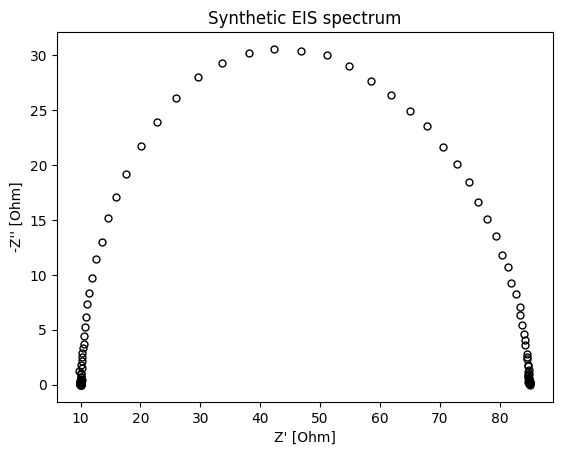

In [4]:
fig, ax = eis.plot_nyquist()
ax.set_title("Synthetic EIS spectrum")
plt.show()

## Normalize by electrode area

Passing `area=` to the constructor (or calling `normalize(area)`) multiplies the
impedance by the electrode area, converting Ω to Ω·cm². Normalization can only
be applied once.

unit after normalization: Ohm cm^2 | normalized: True


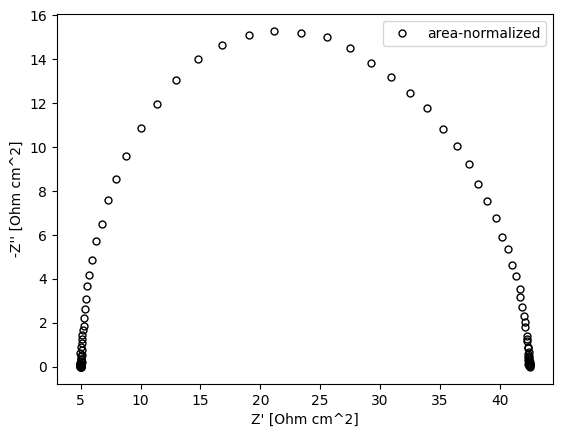

In [5]:
eis_norm = EISData(data.copy(), area=0.5)  # 0.5 cm^2 electrode
print("unit after normalization:", eis_norm.unit, "| normalized:", eis_norm.normalized)

fig, ax = eis_norm.plot_nyquist(label="area-normalized")
ax.legend()
plt.show()

## Trim the frequency range

`cut_frequencies_above` / `cut_frequencies_below` drop points outside a range in
place (use `limit_data(start, end)` for a positional slice).

In [6]:
eis_trimmed = EISData(data.copy())
eis_trimmed.cut_frequencies_above(1e4)
eis_trimmed.cut_frequencies_below(1e-1)
print(f"{len(eis_trimmed.Freq)} of {len(eis.Freq)} points kept")

70 of 100 points kept


## Save and reload (CSV round-trip)

`save_csv` writes the current table; `EISData.from_csv` reads a CSV back in with
automatic column detection.

In [7]:
import os
import tempfile

path = os.path.join(tempfile.mkdtemp(), "spectrum.csv")
eis.save_csv(path)
eis_reloaded = EISData.from_csv(path)
print("Reloaded columns:", eis_reloaded.keys)
print("Identical impedance:", np.allclose(eis_reloaded.Z, eis.Z))

Reloaded columns: ('Zreal (Ohm)', 'Zimag (Ohm)', 'Freq (Hz)')
Identical impedance: True
